## Общая часть

In [16]:
from my_crypto.src.AES import AES
from my_crypto.src.DES import DES
from my_crypto.src.MAGMA import MAGMA
from my_crypto.src.GOST import GOST


encryption = [AES.encrypt, GOST.encrypt, DES.encrypt, MAGMA.encrypt]
decryption = [AES.decrypt, GOST.decrypt, DES.decrypt, MAGMA.decrypt]

def pad(bytes_string: bytes, block_size: int) -> list[bytes]:
    padding_byte = block_size - len(bytes_string) % block_size
    bytes_string += bytes([padding_byte] * padding_byte)
    return [bytes_string[i:i+block_size] for i in range(0, len(bytes_string), block_size)]

def unpad(bytes_string: bytes) -> bytes:
    padding_byte = bytes_string[-1]
    return bytes_string[:-padding_byte]

## ECB

In [2]:

def ECB(algorithm, text: bytes):
    ct = b''

    algorithm_function = algorithm.__func__
    if algorithm_function in encryption:
        if algorithm_function in [AES.encrypt, GOST.encrypt]:
            text = pad(text, 16)
        else:
            text = pad(text, 8)
        for block in text:
            ct += algorithm(block)
    elif algorithm_function in decryption:
        if algorithm_function in [AES.decrypt, GOST.decrypt]:
            blocks = [text[i:i+16] for i in range(0, len(text), 16)]
        else:
            blocks = [text[i:i+8] for i in range(0, len(text), 8)]
        for block in blocks:
            ct += algorithm(block)
        ct = unpad(ct)
    return ct



key = bytes.fromhex("8899aabbccddeeff0011223344556677fedcba98765432100123456789abcdef")
gost = GOST(key)
with open("../files/snapedit_1747409904551.jpg", "rb") as file:
    text = file.read()

# text = bytes.fromhex("1122334455667700ffeeddccbbaa9988")
ct = ECB(gost.encrypt, text)
with open("../files/encrypted.jpg", "wb") as file:
    file.write(ct)
check_text = ECB(gost.decrypt, ct)
with open("../files/decrypted.jpg", "wb") as file:
    file.write(check_text)



перепись шифрования в класс позволило в 4 раза ускорить работу (скорее всего за счёт того, что не надо на каждый блок ключ вычислять, который не меняется для них)\
было:\
\
стало:\
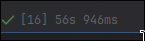\

## CBC

In [3]:
from random import randbytes

def gen_IV(block_size: int) -> bytes:
    return randbytes(block_size)

def xor(block1: bytes, block2: bytes) -> bytes:
    return bytes([a ^ b for a, b in zip(block1, block2)])

def CBC(algorithm, text: bytes, IV: bytes=None) -> tuple[bytes, bytes]:
    ct = b''
    algorithm_function = algorithm.__func__
    if algorithm_function in encryption:
        if algorithm_function in [AES.encrypt, GOST.encrypt]:
            text = pad(text, 16)
            IV = gen_IV(16) if IV is None else IV
        else:
            text = pad(text, 8)
            IV = gen_IV(8) if IV is None else IV
        cipher_block = IV
        for block in text:
            block = xor(block, cipher_block)
            cipher_block = algorithm(block)
            ct += cipher_block
    elif algorithm_function in decryption:
        previous_cipher_block = IV
        if algorithm_function in [AES.decrypt, GOST.decrypt]:
            blocks = [text[i:i+16] for i in range(0, len(text), 16)]
        else:
            blocks = [text[i:i+8] for i in range(0, len(text), 8)]
        for block in blocks:
            open_text = xor(algorithm(block), previous_cipher_block)
            ct += open_text
            previous_cipher_block = block
        ct = unpad(ct)
    return ct, IV

key = b'\x2b\x7e\x15\x16\x28\xae\xd2\xa6\xab\xf7\x15\x88\x09\xcf\x4f\x3c'
# text = b'\x32\x43\xf6\xa8\x88\x5a\x30\x8d\x31\x31\x98\xa2\xe0\x37\x07\x34\x43'
with open("../files/snapedit_1747409904551.jpg", "rb") as file:
    text = file.read()
IV = bytes.fromhex("6fb023c44b3a33ebe8b242ee274f1385")
aes = AES(key)
ctext, IV = CBC(aes.encrypt, text, IV)
with open("../files/encrypted.jpg", "wb") as file:
    file.write(ctext)

check_text, IV = CBC(aes.decrypt, ctext, IV)
with open("../files/decrypted.jpg", "wb") as file:
    file.write(check_text)

Однако CBC оказался ещё в 3 раза быстрее... Возможно дело из-за разницы шифров (включая кривую реализацию)\
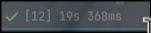

## CFB

In [4]:
def CFB(algorithm, text: bytes, IV: bytes=None, mode: str=None) -> tuple[bytes, bytes]:
    ct = b''
    algorithm_function = algorithm.__func__
    if mode is None or mode == 'e':
        if algorithm_function in [AES.encrypt, GOST.encrypt]:
            blocks = [text[i:i+16] for i in range(0, len(text), 16)]
            IV = gen_IV(16) if IV is None else IV
        else:
            blocks = [text[i:i+8] for i in range(0, len(text), 8)]
            IV = gen_IV(8) if IV is None else IV
        cipher_block = IV
        for block in blocks:
            cipher_block = algorithm(cipher_block)
            cipher_block = xor(block, cipher_block)
            ct += cipher_block
    else:
        if algorithm_function in [AES.encrypt, GOST.encrypt]:
            blocks = [text[i:i+16] for i in range(0, len(text), 16)]
        else:
            blocks = [text[i:i+8] for i in range(0, len(text), 8)]
        cipher_block = IV
        for block in blocks:
            cipher_block = algorithm(cipher_block)
            open_text = xor(block, cipher_block)
            ct += open_text
            cipher_block = block
        # ct = unpad(ct)
    return ct, IV

key = b'\x2b\x7e\x15\x16\x28\xae\xd2\xa6\xab\xf7\x15\x88\x09\xcf\x4f\x3c'
# text = b'\x32\x43\xf6\xa8\x88\x5a\x30\x8d\x31\x31\x98\xa2\xe0\x37\x07\x34\xa0'
with open("../files/snapedit_1747409904551.jpg", "rb") as file:
    text = file.read()
IV = bytes.fromhex("6fb023c44b3a33ebe8b242ee274f1385")
aes = AES(key)
ctext, IV = CFB(aes.encrypt, text, IV)


with open("../files/encrypted.jpg", "wb") as file:
    file.write(ctext)

check_text, IV = CFB(aes.encrypt, ctext, IV, 'd')
with open("../files/decrypted.jpg", "wb") as file:
    file.write(check_text)


Видимо из-за отсутствия паддинга всё ещё быстрее стало\
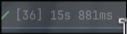

## OFB

In [5]:
def OFB(algorithm, text: bytes, IV: bytes=None) -> tuple[bytes, bytes]:
    ct = b''
    algorithm_function = algorithm.__func__
    if algorithm_function in encryption:
        if algorithm_function in [AES.encrypt, GOST.encrypt]:
            blocks = [text[i:i+16] for i in range(0, len(text), 16)]
            IV = gen_IV(16) if IV is None else IV
        else:
            blocks = [text[i:i+8] for i in range(0, len(text), 8)]
            IV = gen_IV(8) if IV is None else IV
        cipher_block = IV
        for block in blocks:
            cipher_block = algorithm(cipher_block)
            ct += xor(block, cipher_block)

    return ct, IV

key = b'\x2b\x7e\x15\x16\x28\xae\xd2\xa6\xab\xf7\x15\x88\x09\xcf\x4f\x3c'
# text = b'\x32\x43\xf6\xa8\x88\x5a\x30\x8d\x31\x31\x98\xa2\xe0\x37\x07\x34\xa0'
with open("../files/snapedit_1747409904551.jpg", "rb") as file:
    text = file.read()
IV = bytes.fromhex("6fb023c44b3a33ebe8b242ee274f1385")
aes = AES(key)
ctext, IV = OFB(aes.encrypt, text, IV)

with open("../files/encrypted.jpg", "wb") as file:
    file.write(ctext)

check_text, IV = OFB(aes.encrypt, ctext, IV)
with open("../files/decrypted.jpg", "wb") as file:
    file.write(check_text)


## CTR

In [6]:
def add_IV(IV: bytes, block_size:int) -> bytes:
    IV = int.from_bytes(IV, byteorder='big')
    IV = (IV + 1) % (1 << 128)
    return IV.to_bytes(block_size, 'big')

def CTR(algorithm, text: bytes, IV: bytes=None) -> tuple[bytes, bytes]:
    ct = b''
    algorithm_function = algorithm.__func__
    if algorithm_function in encryption:
        if algorithm_function in [AES.encrypt, GOST.encrypt]:
            block_size = 16
        else:
            block_size = 8
        blocks = [text[i:i+block_size] for i in range(0, len(text), block_size)]
        IV = gen_IV(block_size) if IV is None else IV

        for block in blocks:
            cipher_block = algorithm(IV)
            ct += xor(block, cipher_block)
            IV = add_IV(IV, block_size)
    return ct, IV

key = b'\x2b\x7e\x15\x16\x28\xae\xd2\xa6\xab\xf7\x15\x88\x09\xcf\x4f\x3c'
# text = b'\x32\x43\xf6\xa8\x88\x5a\x30\x8d\x31\x31\x98\xa2\xe0\x37\x07\x34\xa0'
with open("../files/snapedit_1747409904551.jpg", "rb") as file:
    text = file.read()
IV = bytes.fromhex("6fb023c44b3a33ebe8b242ee274f1385")
aes = AES(key)
ctext, IV = CTR(aes.encrypt, text, IV)
#
with open("../files/encrypted.jpg", "wb") as file:
    file.write(ctext)
#
IV = bytes.fromhex("6fb023c44b3a33ebe8b242ee274f1385")
check_text, IV = CTR(aes.encrypt, ctext, IV)

# check_text, IV = OFB(aes.encrypt, ctext, IV)
with open("../files/decrypted.jpg", "wb") as file:
    file.write(check_text)

# with open("decrypted.jpg", "rb") as file:
#     check_text = file.read()
#
# for i in range(len(text)):
#     if text[i] != check_text:
#         print(i)